# The University of Azad Jammu and Kashmir
## Department of Software Engineering — Digital Image Processing Lab
### Lab Task # 03 — Image Enhancement and Intensity Transformations

| | |
|---|---|
| **Name** | Sahadat Ali |
| **Roll No** | 2024-SE-36 |
| **Semester / Session** | Fifth / 2024-28 (SE) |
| **Lab Instructor** | Engr. Fahad Nisar |
| **Assigned / Due** | November 02, 2026 / November 09, 2026, 11:59 PM |

**Objective:** calculate, implement and compare grayscale intensity transformations, histogram enhancement and thresholding while preventing overflow and interpreting their effects.

**Conventions used throughout:** every dry run is done by hand first and then verified in Python; arithmetic is done in a wider type (int16 / float64), results are clipped to 0–255 before the conversion to uint8 (fractions are truncated unless rounding is requested); all images are displayed with the grayscale limits 0–255.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("NumPy", np.__version__, "| OpenCV", cv2.__version__)

STUDENT_NAME = "Sahadat Ali"
ROLL_NO = "2024-SE-36"

tables_log = {}   # every printed table is also kept here (used for the Word report)
checks_log = {}   # every verification is also kept here
S = {}            # measured values that are quoted in the observations

def _fmt(v):
    if isinstance(v, (bool, np.bool_)):
        return "Yes" if v else "No"
    if isinstance(v, (int, np.integer)):
        return str(int(v))
    if isinstance(v, (float, np.floating)):
        s = f"{float(v):.4f}".rstrip("0").rstrip(".")
        return "0" if s in ("-0", "") else s
    return str(v)

def print_table(key, title, headers, rows):
    rows = [[_fmt(c) for c in r] for r in rows]
    headers = [str(h) for h in headers]
    tables_log[key] = dict(title=title, headers=headers, rows=rows)
    w = [max(len(h), *(len(r[i]) for r in rows)) for i, h in enumerate(headers)]
    print(title)
    print(" | ".join(h.center(w[i]) for i, h in enumerate(headers)))
    print("-+-".join("-" * x for x in w))
    for r in rows:
        print(" | ".join(c.center(w[i]) for i, c in enumerate(r)))
    print()

def check(key, label, cond):
    ok = bool(cond)
    checks_log.setdefault(key, []).append((label, ok))
    print(("PASS - " if ok else "FAIL - ") + label)
    assert ok, label

def u8(x):
    """Safe conversion: clip to 0-255 first, then truncate to uint8."""
    return np.clip(x, 0, 255).astype(np.uint8)

def show(images, titles, ncols=None, size=3.6):
    n = len(images)
    ncols = ncols or n
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + 0.4))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)   # fixed display range 0-255
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def hist_ax(ax, im, title):
    ax.hist(im.ravel(), bins=256, range=(0, 256), color="#444444")
    ax.set_xlim(0, 256)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Intensity level")
    ax.set_ylabel("Number of pixels")

NumPy 2.5.4 | OpenCV 5.0.0


## Load and validate the image
The input file is a colour photo; `cv2.IMREAD_GRAYSCALE` converts it to a single 8-bit channel. The result is validated (2-D, uint8, at least 300 × 300) and a read-only reference copy `original` is kept unchanged.

Shape : (1452, 1160)
dtype : uint8
Min   : 14
Max   : 255
Image properties
      Property      |    Value   
--------------------+------------
Shape (rows x cols) | 1452 x 1160
       dtype        |    uint8   
      Minimum       |      14    
      Maximum       |     255    



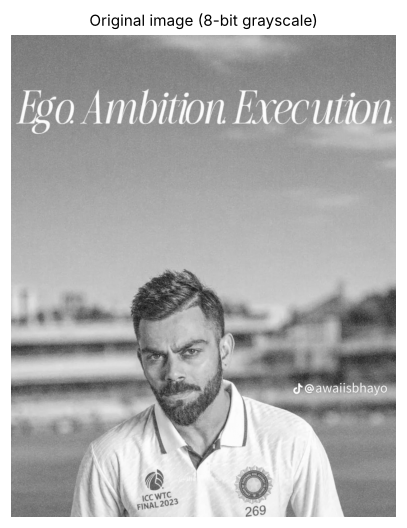

In [2]:
IMAGE_PATH = "input_image.png"        # my selected image (same folder as this notebook)

img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)   # 8-bit single channel
assert img is not None, "Image could not be loaded - check IMAGE_PATH"
assert img.ndim == 2 and img.dtype == np.uint8, "Image must be 8-bit grayscale"
assert min(img.shape) >= 300, "Image must be at least 300 x 300 pixels"

original = img.copy()          # untouched reference copy
original.flags.writeable = False   # any accidental in-place change now raises an error

print("Shape :", original.shape)
print("dtype :", original.dtype)
print("Min   :", int(original.min()))
print("Max   :", int(original.max()))
S["shape"] = original.shape
S["min"], S["max"] = int(original.min()), int(original.max())
S["mean"] = float(original.mean())
print_table("img_props", "Image properties", ["Property", "Value"],
            [["Shape (rows x cols)", f"{original.shape[0]} x {original.shape[1]}"],
             ["dtype", str(original.dtype)], ["Minimum", int(original.min())],
             ["Maximum", int(original.max())]])
show([original], ["Original image (8-bit grayscale)"], size=4.5)

---
## 1. Brightness adjustment
**Task:** Produce a brighter and a darker image with β = +40 and β = −40, implement +40 again with nested loops and verify that it matches NumPy.

### Dry run (done before coding)
Pixels [30, 80, 128, 180, 240]: calculate brightness +40 and −40; show raw values, clipping and final uint8 values; explain any lost detail.

In [3]:
P = np.array([30, 80, 128, 180, 240])

raw_p = P + 40
clip_p = np.clip(raw_p, 0, 255)
fin_p = clip_p.astype(np.uint8)
wrap_p = P.astype(np.uint8) + np.uint8(40)          # what plain uint8 arithmetic would give

raw_m = P - 40
clip_m = np.clip(raw_m, 0, 255)
fin_m = clip_m.astype(np.uint8)
wrap_m = P.astype(np.uint8) - np.uint8(40)

print_table("dry1_plus", "Dry run 1(a): brightness +40",
            ["r", "r + 40 (raw)", "After clipping 0–255", "Final uint8", "Plain uint8 (wraps – wrong)"],
            list(zip(P, raw_p, clip_p, fin_p, wrap_p)))
print_table("dry1_minus", "Dry run 1(b): brightness −40",
            ["r", "r − 40 (raw)", "After clipping 0–255", "Final uint8", "Plain uint8 (wraps – wrong)"],
            list(zip(P, raw_m, clip_m, fin_m, wrap_m)))

check("dry1", "+40 hand calculation [70,120,168,220,255] matches Python", np.array_equal(fin_p, [70, 120, 168, 220, 255]))
check("dry1", "−40 hand calculation [0,40,88,140,200] matches Python", np.array_equal(fin_m, [0, 40, 88, 140, 200]))
check("dry1", "Same pixels through the image function u8() give the same result",
      np.array_equal(u8(P.astype(np.int16) + 40), fin_p) and np.array_equal(u8(P.astype(np.int16) - 40), fin_m))

Dry run 1(a): brightness +40
 r  | r + 40 (raw) | After clipping 0–255 | Final uint8 | Plain uint8 (wraps – wrong)
----+--------------+----------------------+-------------+----------------------------
 30 |      70      |          70          |      70     |              70            
 80 |     120      |         120          |     120     |             120            
128 |     168      |         168          |     168     |             168            
180 |     220      |         220          |     220     |             220            
240 |     280      |         255          |     255     |              24            

Dry run 1(b): brightness −40
 r  | r − 40 (raw) | After clipping 0–255 | Final uint8 | Plain uint8 (wraps – wrong)
----+--------------+----------------------+-------------+----------------------------
 30 |     -10      |          0           |      0      |             246            
 80 |      40      |          40          |      40     |              40        

**Dry-run explanation**

Lost detail: with +40 the pixel 240 becomes 280, which is clipped to 255, so 25 grey levels of information are cut off. Every input r ≥ 215 ends at 255, so (for example) 230 and 240 become indistinguishable. With −40 the pixel 30 becomes −10 and is clipped to 0; every input r ≤ 40 ends at 0, so dark detail disappears.

Why a wider type is needed: if the arithmetic stayed in uint8 the results would wrap modulo 256 – 240 + 40 would give 24 (very dark instead of very bright) and 30 − 40 would give 246 (very bright instead of very dark), as the last column of the tables shows.

### Implementation on the image

Mean: original 164.86 | +40 -> 202.38 | -40 -> 124.86
Pixels at 255 after +40: 188553  (original: 177)
Pixels at 0   after -40: 1749  (original: 0)
Pixels that would wrap around with plain uint8 +40: 185207


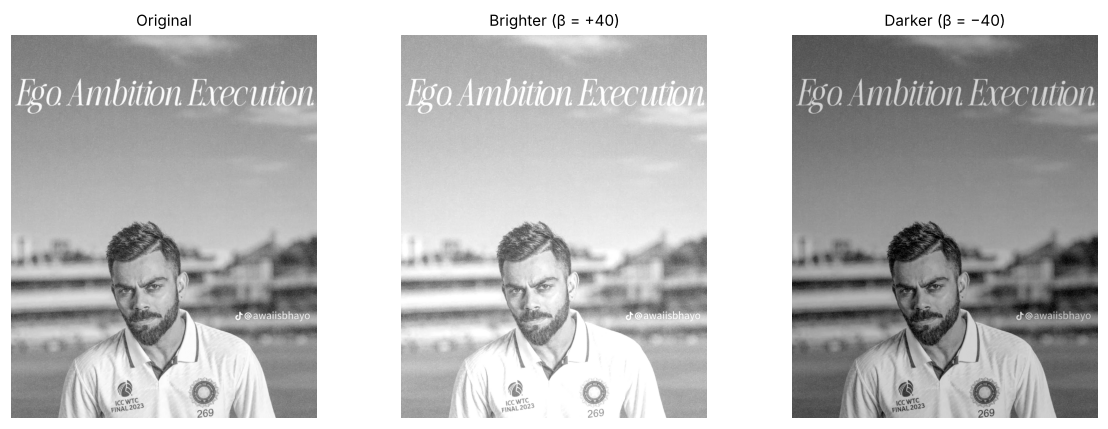

In [4]:
f16 = original.astype(np.int16)              # wider type so +40 / -40 cannot wrap around
bright = u8(f16 + 40)
dark = u8(f16 - 40)

naive = original + np.uint8(40)              # WRONG: stays uint8, values > 255 wrap to small numbers
S["naive_wrapped"] = int((original >= 216).sum())
S["b_mean"], S["d_mean"] = float(bright.mean()), float(dark.mean())
S["b_sat"], S["d_sat"] = int((bright == 255).sum()), int((dark == 0).sum())
S["o_sat255"], S["o_sat0"] = int((original == 255).sum()), int((original == 0).sum())

show([original, bright, dark],
     ["Original", "Brighter (β = +40)", "Darker (β = −40)"])
print(f"Mean: original {original.mean():.2f} | +40 -> {bright.mean():.2f} | -40 -> {dark.mean():.2f}")
print(f"Pixels at 255 after +40: {S['b_sat']}  (original: {S['o_sat255']})")
print(f"Pixels at 0   after -40: {S['d_sat']}  (original: {S['o_sat0']})")
print(f"Pixels that would wrap around with plain uint8 +40: {S['naive_wrapped']}")

In [5]:
# +40 with nested loops (explicit clipping for every pixel)
rows, cols = original.shape
loop_bright = np.zeros_like(original)
for i in range(rows):
    for j in range(cols):
        v = int(original[i, j]) + 40
        if v > 255:
            v = 255
        loop_bright[i, j] = v

check("op1", "Nested-loop +40 result equals the NumPy result", np.array_equal(loop_bright, bright))

PASS - Nested-loop +40 result equals the NumPy result


**Observation:** Adding 40 raised the mean intensity from 164.9 to 202.4 and subtracting 40 lowered it to 124.9. Brightness only shifts all pixels by the same amount, but clipping removed information: pixels at 255 grew from 177 to 188,553 after +40 (this image is already bright, so the bright sky and the white shirt lose their tone differences), and pixels at 0 grew from 0 to 1,749 after −40. With plain uint8 arithmetic 185,207 bright pixels (r ≥ 216) would have wrapped around to dark values. The nested-loop result is identical to the NumPy result, but NumPy does it in one vectorised step.

---
## 2. Linear contrast from zero
**Task:** Apply s = αr + β with α = 1.5 and β = 0, then compare brightness and highlight clipping with the original.

### Dry run (done before coding)
Pixels [30, 80, 128, 180, 240]: calculate 1.5r, clip to 0–255, truncate and identify the saturated pixels.

In [6]:
raw2 = P * 1.5
clip2 = np.clip(raw2, 0, 255)
fin2 = clip2.astype(np.uint8)                          # truncation
sat2 = raw2 >= 255

print_table("dry2", "Dry run 2: s = 1.5 r",
            ["r", "1.5 r (raw)", "After clipping 0–255", "Truncated uint8", "Saturated?"],
            list(zip(P, raw2, clip2, fin2, sat2)))
check("dry2", "Hand calculation [45,120,192,255,255] matches Python", np.array_equal(fin2, [45, 120, 192, 255, 255]))
check("dry2", "Saturated pixels are exactly r = 180 and r = 240", list(P[sat2]) == [180, 240])

Dry run 2: s = 1.5 r
 r  | 1.5 r (raw) | After clipping 0–255 | Truncated uint8 | Saturated?
----+-------------+----------------------+-----------------+-----------
 30 |      45     |          45          |        45       |     No    
 80 |     120     |         120          |       120       |     No    
128 |     192     |         192          |       192       |     No    
180 |     270     |         255          |       255       |    Yes    
240 |     360     |         255          |       255       |    Yes    

PASS - Hand calculation [45,120,192,255,255] matches Python
PASS - Saturated pixels are exactly r = 180 and r = 240


**Dry-run explanation**

The pixels 180 and 240 give 270 and 360, which are above 255, so both are saturated and become 255 although they were 60 grey levels apart. In general every pixel with r ≥ 170 is saturated, because 1.5 × 170 = 255.

All values in this example (45, 120, 192) are whole numbers, so truncation does not change them; it would only matter for values such as 1.5 × 31 = 46.5 → 46.

### Implementation on the image

Mean brightness : original 164.86 -> 227.21
Pixels at 255   : original 177 (0.01 %) -> 763542 (45.33 %)
Every input r >= 170 is saturated, because 1.5 x 170 = 255.


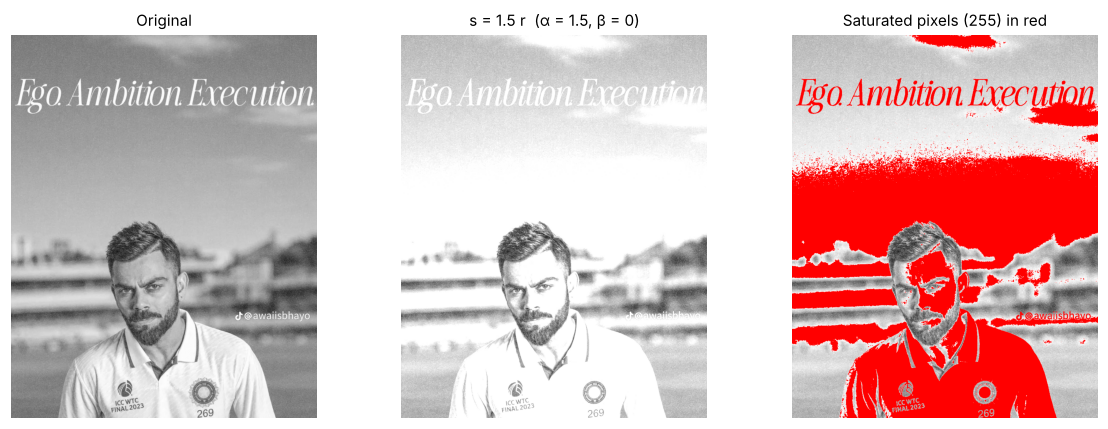

In [7]:
c15 = u8(original.astype(np.float64) * 1.5)           # s = 1.5 r + 0, clip, then truncate

sat_mask = c15 == 255
overlay = np.stack([c15] * 3, axis=-1).copy()
overlay[sat_mask] = [255, 0, 0]                        # clipped pixels in red

S["c15_mean"] = float(c15.mean())
S["c15_sat"] = int(sat_mask.sum())
S["c15_sat_pct"] = 100 * sat_mask.mean()
S["o_sat_pct"] = 100 * (original == 255).mean()

show([original, c15, overlay],
     ["Original", "s = 1.5 r  (α = 1.5, β = 0)", "Saturated pixels (255) in red"])
print(f"Mean brightness : original {original.mean():.2f} -> {c15.mean():.2f}")
print(f"Pixels at 255   : original {S['o_sat255']} ({S['o_sat_pct']:.2f} %) -> {S['c15_sat']} ({S['c15_sat_pct']:.2f} %)")
print("Every input r >= 170 is saturated, because 1.5 x 170 = 255.")

**Observation:** Multiplying by 1.5 raised the mean from 164.9 to 227.2, but the standard deviation did not grow (40.1 → 37.9) because of clipping. 45.3 % of the pixels are now saturated at 255 (originally 0.01 %), as the red overlay shows: every pixel with r ≥ 170 is merged into pure white, so most of the sky and the shirt lose their detail. Scaling from zero therefore changes brightness much more than useful contrast and clips the highlights heavily.

---
## 3. Contrast centered at 128
**Task:** Apply s = (r − 128)α + 128 with α = 1.5 and α = 0.5 and compare both results with linear contrast from zero.

### Dry run (done before coding)
Pixels [30, 80, 128, 180, 240]: calculate (r − 128)α + 128 for α = 1.5 and 0.5 with intermediate values and clipping; explain the result at r = 128.

In [8]:
def dry3(alpha):
    d = P - 128
    m = d * alpha
    raw = m + 128
    fin = np.clip(raw, 0, 255).astype(np.uint8)
    return d, m, raw, fin

d, m, raw, fin_a15 = dry3(1.5)
print_table("dry3_a15", "Dry run 3(a): α = 1.5",
            ["r", "r − 128", "× 1.5", "+ 128 (raw)", "Clipped & truncated"], list(zip(P, d, m, raw, fin_a15)))
d, m, raw, fin_a05 = dry3(0.5)
print_table("dry3_a05", "Dry run 3(b): α = 0.5",
            ["r", "r − 128", "× 0.5", "+ 128 (raw)", "Clipped & truncated"], list(zip(P, d, m, raw, fin_a05)))

check("dry3", "α = 1.5 hand calculation [0,56,128,206,255] matches", np.array_equal(fin_a15, [0, 56, 128, 206, 255]))
check("dry3", "α = 0.5 hand calculation [79,104,128,154,184] matches", np.array_equal(fin_a05, [79, 104, 128, 154, 184]))
check("dry3", "r = 128 maps to 128 for both α (fixed point)", fin_a15[2] == 128 and fin_a05[2] == 128)

Dry run 3(a): α = 1.5
 r  | r − 128 | × 1.5 | + 128 (raw) | Clipped & truncated
----+---------+-------+-------------+--------------------
 30 |   -98   |  -147 |     -19     |          0         
 80 |   -48   |  -72  |      56     |          56        
128 |    0    |   0   |     128     |         128        
180 |    52   |   78  |     206     |         206        
240 |   112   |  168  |     296     |         255        

Dry run 3(b): α = 0.5
 r  | r − 128 | × 0.5 | + 128 (raw) | Clipped & truncated
----+---------+-------+-------------+--------------------
 30 |   -98   |  -49  |      79     |          79        
 80 |   -48   |  -24  |     104     |         104        
128 |    0    |   0   |     128     |         128        
180 |    52   |   26  |     154     |         154        
240 |   112   |   56  |     184     |         184        

PASS - α = 1.5 hand calculation [0,56,128,206,255] matches
PASS - α = 0.5 hand calculation [79,104,128,154,184] matches
PASS - r = 128 maps to

**Dry-run explanation**

At r = 128 the term (r − 128) is zero, so the output is 128 whatever α is: 128 is the pivot (fixed point) of this transform. Pixels below 128 are pushed away from the pivot (downwards) and pixels above 128 upwards when α > 1; when α < 1 all pixels are pulled towards 128.

With α = 1.5 the pixel 30 gives −19 → clipped to 0 and 240 gives 296 → clipped to 255, so both ends of the range clip; with α = 0.5 nothing clips and the range shrinks to 79–184.

### Implementation on the image

Comparison of contrast operations
      Image       |  Mean  | Std. dev. | Min | Max | % pixels = 0 | % pixels = 255
------------------+--------+-----------+-----+-----+--------------+---------------
     Original     | 164.86 |   40.05   |  14 | 255 |      0       |      0.01     
1.5 r (from zero) | 227.21 |    37.9   |  21 | 255 |      0       |     45.33     
(r−128)·1.5 + 128 | 178.96 |    53.1   |  0  | 255 |     0.16     |     11.62     
(r−128)·0.5 + 128 | 146.18 |   20.03   |  71 | 191 |      0       |       0       



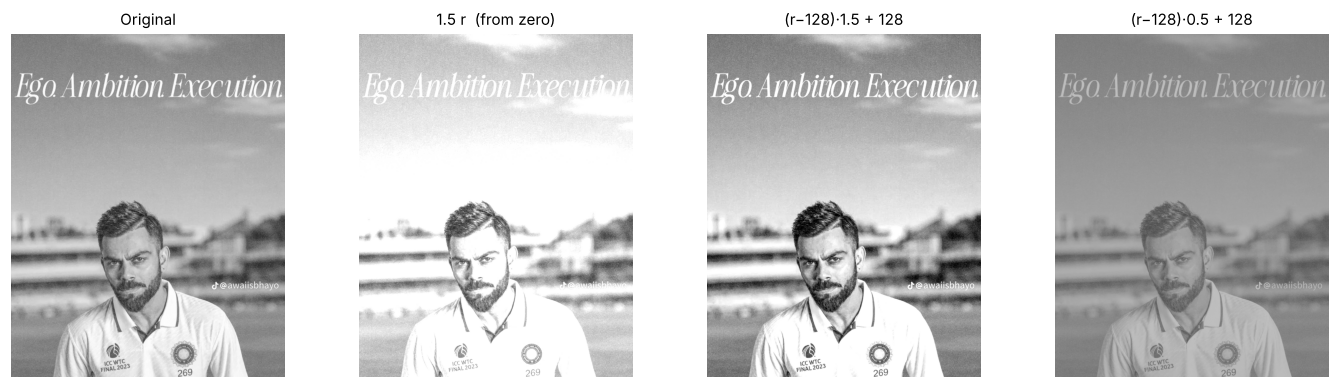

In [9]:
def centered_contrast(a, alpha):
    return u8((a.astype(np.float64) - 128) * alpha + 128)

cc_up = centered_contrast(original, 1.5)
cc_dn = centered_contrast(original, 0.5)

def stats_row(name, a):
    return [name, round(float(a.mean()), 2), round(float(a.std()), 2), int(a.min()), int(a.max()),
            round(100 * float((a == 0).mean()), 2), round(100 * float((a == 255).mean()), 2)]

print_table("cmp3", "Comparison of contrast operations",
            ["Image", "Mean", "Std. dev.", "Min", "Max", "% pixels = 0", "% pixels = 255"],
            [stats_row("Original", original),
             stats_row("1.5 r (from zero)", c15),
             stats_row("(r−128)·1.5 + 128", cc_up),
             stats_row("(r−128)·0.5 + 128", cc_dn)])
S["cc_up_mean"], S["cc_dn_mean"] = float(cc_up.mean()), float(cc_dn.mean())
S["cc_up_std"], S["cc_dn_std"], S["o_std"], S["c15_std"] = float(cc_up.std()), float(cc_dn.std()), float(original.std()), float(c15.std())
S["cc_up_sat"] = 100 * float((cc_up == 255).mean()); S["cc_up_zero"] = 100 * float((cc_up == 0).mean())

show([original, c15, cc_up, cc_dn],
     ["Original", "1.5 r  (from zero)", "(r−128)·1.5 + 128", "(r−128)·0.5 + 128"], ncols=4, size=3.2)

**Observation:** Centered contrast with α = 1.5 increases the standard deviation to 53.1 (original 40.1). The mean rises only moderately (164.9 → 179.0), because most pixels lie above the pivot 128 and are pushed upwards; it clips mainly at the bright end (0.16 % of pixels become 0 and 11.6 % become 255), which is far fewer saturated pixels than 1.5r from zero (45.3 %), and the contrast is higher (standard deviation 53.1 against 37.9 for 1.5r). With α = 0.5 the output is squeezed into 71–191 (standard deviation 20.0), nothing clips and the image looks flat and washed out. So the centered form changes mainly contrast around a mid-grey pivot, whereas αr from zero mixes a contrast change with a strong brightness change.

---
## 4. Image negative
**Task:** Create the image negative s = 255 − r and explain one situation where it helps inspection.

### Dry run (done before coding)
Pixels [30, 80, 128, 180, 240]: calculate 255 − r, apply the negative again and compare with the original.

In [10]:
neg_p = 255 - P
neg_neg = 255 - neg_p
print_table("dry4", "Dry run 4: image negative",
            ["r", "s = 255 − r", "255 − s (negative again)", "Equals original?"],
            list(zip(P, neg_p, neg_neg, neg_neg == P)))
check("dry4", "Hand calculation [225,175,127,75,15] matches", np.array_equal(neg_p, [225, 175, 127, 75, 15]))
check("dry4", "Applying the negative twice returns the original pixels", np.array_equal(neg_neg, P))

Dry run 4: image negative
 r  | s = 255 − r | 255 − s (negative again) | Equals original?
----+-------------+--------------------------+-----------------
 30 |     225     |            30            |       Yes       
 80 |     175     |            80            |       Yes       
128 |     127     |           128            |       Yes       
180 |      75     |           180            |       Yes       
240 |      15     |           240            |       Yes       

PASS - Hand calculation [225,175,127,75,15] matches
PASS - Applying the negative twice returns the original pixels


**Dry-run explanation**

The negative reverses the order of the grey levels (dark ↔ bright). Applying it a second time gives 255 − (255 − r) = r, so the original pixels [30, 80, 128, 180, 240] are recovered exactly – the operation is lossless.

Because 255 is odd, no integer pixel is its own negative: 128 becomes 127 (the mathematical fixed point is 127.5).

### Implementation on the image

PASS - Negative of the negative equals the original
Mean: original 164.86 -> negative 90.14 (sum of the two means = 255.0 )


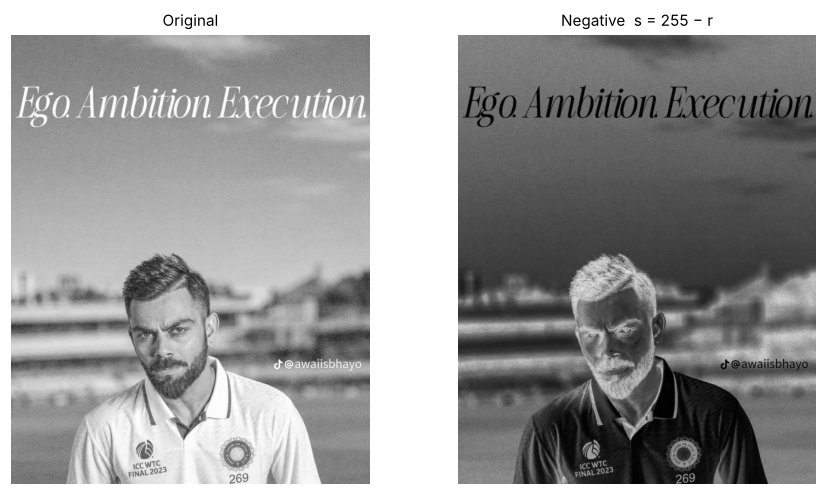

In [11]:
negative = u8(255 - original.astype(np.int16))
show([original, negative], ["Original", "Negative  s = 255 − r"], size=4.2)
check("op4", "Negative of the negative equals the original", np.array_equal(u8(255 - negative.astype(np.int16)), original))
print("Mean: original", round(float(original.mean()), 2), "-> negative", round(float(negative.mean()), 2),
      "(sum of the two means =", round(float(original.mean() + negative.mean()), 2), ")")

**Observation:** The negative reverses light and dark (mean 164.9 → 90.1; the two means add up to 255) and applying it twice restores the original exactly. Situation where it helps inspection: when white or light-grey detail is embedded in a large dark region (for example in X-ray or scanned film images), the negative turns that detail into dark marks on a light background, which is often easier to examine.

---
## 5. Gamma correction
**Task:** Apply s = 255 (r/255)^γ for γ = 0.5 and γ = 2.0, compare the effect on dark regions and confirm that 0 and 255 stay fixed.

### Dry run (done before coding)
Pixels [0, 64, 128, 192, 255]: show normalisation, power and scaling for γ = 0.5 and 2.0 (full precision, truncate only the final output); explain any difference from the rounded slide example.

In [12]:
def gamma_correct(a, g):
    """s = 255 (r/255)^g  –  full precision, truncate only at the very end."""
    return u8(255.0 * (a.astype(np.float64) / 255.0) ** g)

P5 = np.array([0, 64, 128, 192, 255])

def dry5(g):
    norm = P5 / 255.0
    powr = norm ** g
    scaled = 255.0 * powr
    final = scaled.astype(np.uint8)       # truncate only here
    return norm, powr, scaled, final

n, p_, s_, f05 = dry5(0.5)
print_table("dry5_g05", "Dry run 5(a): γ = 0.5",
            ["r", "r/255", "(r/255)^0.5", "255 × power", "Truncated output"],
            [[a, f'{b:.6f}', f'{c:.6f}', f'{d:.4f}', e] for a, b, c, d, e in zip(P5, n, p_, s_, f05)])
n, p_, s_, f20 = dry5(2.0)
print_table("dry5_g20", "Dry run 5(b): γ = 2.0",
            ["r", "r/255", "(r/255)^2", "255 × power", "Truncated output"],
            [[a, f'{b:.6f}', f'{c:.6f}', f'{d:.4f}', e] for a, b, c, d, e in zip(P5, n, p_, s_, f20)])

# comparison with a "rounded slide example": normalised value rounded to 2 decimals (0.25, 0.50, 0.75)
rows = []
for g, full in [(0.5, f05), (2.0, f20)]:
    nr = np.round(P5 / 255.0, 2)
    sl = (255 * nr ** g).astype(np.uint8)
    rows += [[g, a, b, c, int(c) - int(b)] for a, b, c in zip(P5, full, sl)][1:4]
print_table("dry5_cmp", "Full precision vs. rounded-normalisation (slide-style) values",
            ["γ", "r", "Full precision (truncated)", "Rounded r/255 to 2 d.p.", "Difference"], rows)

check("dry5", "γ = 0.5 hand calculation [0,127,180,221,255] matches", np.array_equal(f05, [0, 127, 180, 221, 255]))
check("dry5", "γ = 2.0 hand calculation [0,16,64,144,255] matches", np.array_equal(f20, [0, 16, 64, 144, 255]))
check("dry5", "Image function gives the same result for the dry-run pixels",
      np.array_equal(gamma_correct(P5, 0.5), f05) and np.array_equal(gamma_correct(P5, 2.0), f20))

Dry run 5(a): γ = 0.5
 r  |  r/255   | (r/255)^0.5 | 255 × power | Truncated output
----+----------+-------------+-------------+-----------------
 0  | 0.000000 |   0.000000  |    0.0000   |        0        
 64 | 0.250980 |   0.500979  |   127.7498  |       127       
128 | 0.501961 |   0.708492  |   180.6654  |       180       
192 | 0.752941 |   0.867722  |   221.2691  |       221       
255 | 1.000000 |   1.000000  |   255.0000  |       255       

Dry run 5(b): γ = 2.0
 r  |  r/255   | (r/255)^2 | 255 × power | Truncated output
----+----------+-----------+-------------+-----------------
 0  | 0.000000 |  0.000000 |    0.0000   |        0        
 64 | 0.250980 |  0.062991 |   16.0627   |        16       
128 | 0.501961 |  0.251965 |   64.2510   |        64       
192 | 0.752941 |  0.566920 |   144.5647  |       144       
255 | 1.000000 |  1.000000 |   255.0000  |       255       

Full precision vs. rounded-normalisation (slide-style) values
 γ  |  r  | Full precision (truncated)

**Dry-run explanation**

Method: normalise (r/255), raise to the power γ, then scale back (× 255). All intermediate values are kept at full precision and only the final result is truncated.

Difference from the rounded slide example: 64/255 is 0.250980…, not exactly 0.25, and 128/255 is 0.501961…, not 0.50. If the normalised value is rounded to two decimals (0.25, 0.50, 0.75) before the power is taken, the outputs change by up to 1 grey level (for example γ = 2.0, r = 64: 16.06 → 16 at full precision but 15.94 → 15 with 0.25). The slide values were not available to me, so this comparison assumes the slide rounds r/255 to two decimals.

End points: 0^γ = 0 and 1^γ = 1 for every γ, so 0 stays 0 and 255 stays 255.

### Implementation on the image

Effect of gamma on the dark regions (pixels with r < 64)
 Image   | Mean of dark-region pixels | Mean of whole image
---------+----------------------------+--------------------
Original |          52.8482           |       164.8567     
γ = 0.5  |          115.0962          |       202.8599     
γ = 2.0  |          10.7948           |       112.4315     

PASS - 0 and 255 stay fixed for γ = 0.5
PASS - 0 and 255 stay fixed for γ = 2.0


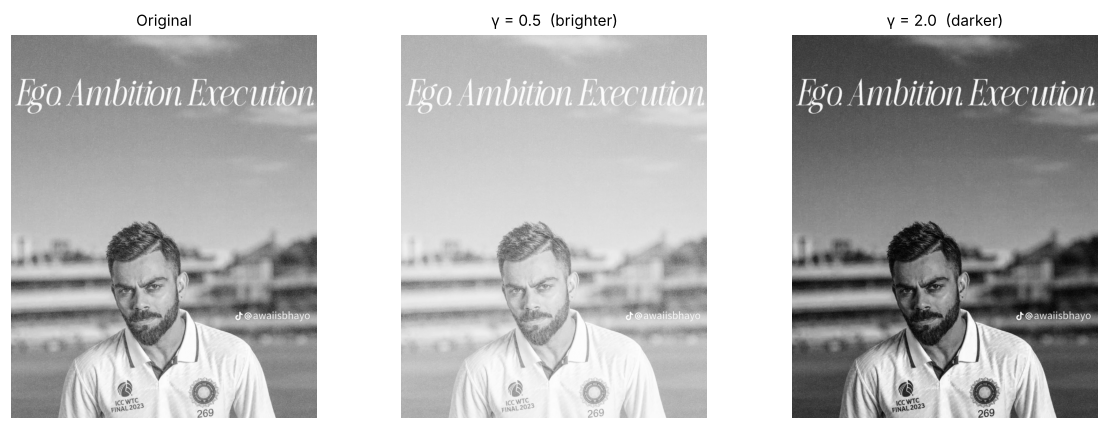

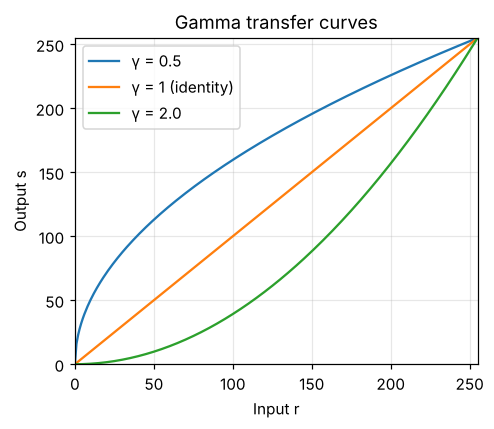

In [13]:
g05 = gamma_correct(original, 0.5)
g20 = gamma_correct(original, 2.0)

show([original, g05, g20], ["Original", "γ = 0.5  (brighter)", "γ = 2.0  (darker)"])

# transfer curves
r = np.arange(256)
plt.figure(figsize=(4.6, 4))
for g, lab in [(0.5, "γ = 0.5"), (1.0, "γ = 1 (identity)"), (2.0, "γ = 2.0")]:
    plt.plot(r, 255 * (r / 255) ** g, label=lab)
plt.xlabel("Input r"); plt.ylabel("Output s"); plt.title("Gamma transfer curves")
plt.xlim(0, 255); plt.ylim(0, 255); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

dark_region = original < 64
S["dark_frac"] = 100 * float(dark_region.mean())
S["dr_o"], S["dr_05"], S["dr_20"] = (float(x[dark_region].mean()) for x in (original, g05, g20))
print_table("cmp5", "Effect of gamma on the dark regions (pixels with r < 64)",
            ["Image", "Mean of dark-region pixels", "Mean of whole image"],
            [["Original", S["dr_o"], original.mean()], ["γ = 0.5", S["dr_05"], g05.mean()], ["γ = 2.0", S["dr_20"], g20.mean()]])

endpoints = np.array([0, 255], dtype=np.uint8)
check("op5", "0 and 255 stay fixed for γ = 0.5", np.array_equal(gamma_correct(endpoints, 0.5), endpoints))
check("op5", "0 and 255 stay fixed for γ = 2.0", np.array_equal(gamma_correct(endpoints, 2.0), endpoints))

**Observation:** γ = 0.5 brightened the image (mean 164.9 → 202.9) and lifted the dark regions strongly: the 1.1 % of pixels below 64 (hair, beard and shadows) had a mean of 52.8 and now have 115.1. γ = 2.0 darkened the image (mean 112.4) and crushed those shadows to a mean of 10.8; because this image is bright, γ = 2.0 gives the more balanced overall look while γ = 0.5 pushes the sky towards white. 0 and 255 stay fixed for both values because 0^γ = 0 and 1^γ = 1. Convention: with s = 255 (r/255)^γ, γ < 1 brightens and γ > 1 darkens; many libraries and display standards use the inverse form s = 255 (r/255)^(1/γ), so the convention must always be checked.

---
## 6. Grayscale histogram
**Task:** Plot a labelled 256-bin histogram over 0–256 for the original image and interpret it in two sentences.

### Dry run (done before coding)
A = [[0, 50, 50, 100], [100, 150, 200, 255]]: find the non-zero frequencies, probabilities and total pixel count; explain why a histogram does not show pixel positions.

In [14]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]])
vals, freq = np.unique(A, return_counts=True)
total = A.size
print_table("dry6", "Dry run 6: histogram of A (non-zero frequencies)",
            ["Intensity", "Frequency", "Probability = freq / 8"],
            [[v, f, f / total] for v, f in zip(vals, freq)])
print("Total number of pixels:", total, "| sum of frequencies:", int(freq.sum()), "| sum of probabilities:", freq.sum() / total)

A_shuffled = np.array([[255, 100, 0, 50], [200, 100, 50, 150]])      # same values, different positions
h1 = np.bincount(A.ravel(), minlength=256)
h2 = np.bincount(A_shuffled.ravel(), minlength=256)
check("dry6", "Frequencies [1,2,2,1,1,1] for values [0,50,100,150,200,255] and 8 pixels",
      list(freq) == [1, 2, 2, 1, 1, 1] and total == 8)
check("dry6", "cv2.calcHist matches the hand count",
      np.array_equal(cv2.calcHist([A.astype(np.uint8)], [0], None, [256], [0, 256]).ravel().astype(int), h1))
check("dry6", "A different arrangement of the same pixels has an identical histogram", np.array_equal(h1, h2) and not np.array_equal(A, A_shuffled))

Dry run 6: histogram of A (non-zero frequencies)
Intensity | Frequency | Probability = freq / 8
----------+-----------+-----------------------
    0     |     1     |         0.125         
    50    |     2     |          0.25         
   100    |     2     |          0.25         
   150    |     1     |         0.125         
   200    |     1     |         0.125         
   255    |     1     |         0.125         

Total number of pixels: 8 | sum of frequencies: 8 | sum of probabilities: 1.0
PASS - Frequencies [1,2,2,1,1,1] for values [0,50,100,150,200,255] and 8 pixels
PASS - cv2.calcHist matches the hand count
PASS - A different arrangement of the same pixels has an identical histogram


**Dry-run explanation**

The table lists only the intensities that occur (all other frequencies are zero). The total is 8 pixels (2 × 4), the frequencies add up to 8 and the probabilities (frequency / 8) add up to 1.

A histogram does not show pixel positions because it only counts how many pixels have each intensity; the pixels are tallied by value and their rows and columns are discarded. The notebook demonstrates this with a rearranged copy of A that has exactly the same histogram although it is a different image.

### Implementation on the image

PASS - cv2.calcHist agrees with np.bincount
Dark (0-63): 1.1 %  |  Mid (64-191): 76.8 %  |  Bright (192-255): 22.2 %
Tallest bin: 183  |  median 164  |  std 40.1


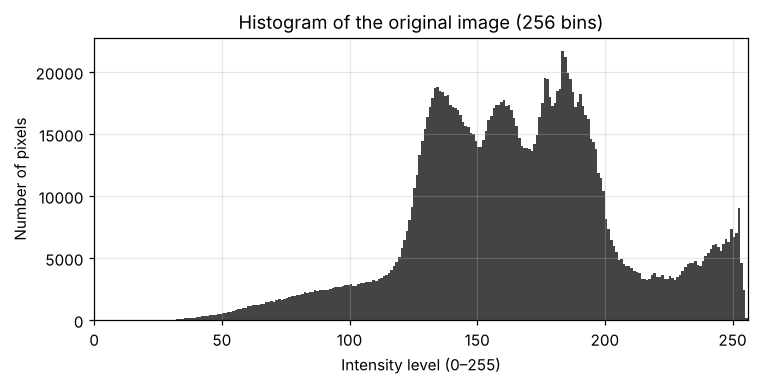

In [15]:
hist = cv2.calcHist([original], [0], None, [256], [0, 256]).ravel()
check("op6", "cv2.calcHist agrees with np.bincount", np.array_equal(hist.astype(int), np.bincount(original.ravel(), minlength=256)))

plt.figure(figsize=(7, 3.6))
plt.hist(original.ravel(), bins=256, range=(0, 256), color="#444444")
plt.xlim(0, 256)
plt.title("Histogram of the original image (256 bins)")
plt.xlabel("Intensity level (0–255)")
plt.ylabel("Number of pixels")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

S["p_dark"] = 100 * float((original < 64).mean())
S["p_mid"] = 100 * float(((original >= 64) & (original < 192)).mean())
S["p_bright"] = 100 * float((original >= 192).mean())
S["peak"] = int(hist.argmax())
S["median"] = float(np.median(original))
S["std"] = float(original.std())
print(f"Dark (0-63): {S['p_dark']:.1f} %  |  Mid (64-191): {S['p_mid']:.1f} %  |  Bright (192-255): {S['p_bright']:.1f} %")
print(f"Tallest bin: {S['peak']}  |  median {S['median']:.0f}  |  std {S['std']:.1f}")

**Observation:** The histogram is concentrated in the bright-to-mid range: 76.8 % of the pixels lie between 64 and 191, in three overlapping peaks near levels 135, 160 and 183 (mostly the sky and the blurred background), plus a small bright bump near 250 (the white shirt and the lettering), while only 1.1 % of the pixels are below 64 and the darkest levels (hair, beard, shadows) form a thin tail. With a mean of 164.9, a median of 164 and a standard deviation of only 40.1, this is a bright, fairly low-contrast image that leaves the darkest quarter of the range almost unused, so contrast enhancement should help.

---
## 7. Global histogram equalization
**Task:** Apply cv2.equalizeHist, show the original/equalized images with their histograms and discuss detail and noise.

### Dry run (done before coding)
Pixels [50, 50, 100, 150]: frequencies, cumulative counts and CDF; map with 255 × CDF and with 255 × (CDF − CDFmin)/(1 − CDFmin) (round to nearest, .5 upward); compare the second with OpenCV.

In [16]:
A7 = np.array([50, 50, 100, 150])
vals7, freq7 = np.unique(A7, return_counts=True)
cum7 = np.cumsum(freq7)
cdf7 = cum7 / A7.size
cdf_min = cdf7[cdf7 > 0].min()

print_table("dry7_cdf", "Dry run 7(a): frequencies, cumulative counts and CDF",
            ["Intensity", "Frequency", "Cumulative count", "CDF = cum / 4"], list(zip(vals7, freq7, cum7, cdf7)))
print("CDFmin (lowest non-zero CDF) =", cdf_min)

half_up = lambda x: np.floor(np.asarray(x) + 0.5).astype(int)      # round to nearest, .5 upward
mapA_raw = 255 * cdf7
mapA = half_up(mapA_raw)
mapB_raw = 255 * (cdf7 - cdf_min) / (1 - cdf_min)
mapB = half_up(mapB_raw)

print_table("dry7_map", "Dry run 7(b): the two mappings",
            ["Intensity", "CDF", "255 × CDF", "Rounded (A)", "(CDF − CDFmin)/(1 − CDFmin)", "× 255", "Rounded (B)"],
            [[v, c, a, ra, (c - cdf_min) / (1 - cdf_min), b, rb] for v, c, a, ra, b, rb in zip(vals7, cdf7, mapA_raw, mapA, mapB_raw, mapB)])

idx = np.searchsorted(vals7, A7)
outA, outB = mapA[idx], mapB[idx]
cv_out = cv2.equalizeHist(A7.astype(np.uint8).reshape(1, -1)).ravel()
print("Output list with mapping A (255 × CDF)                 :", outA.tolist())
print("Output list with mapping B (CDFmin-corrected)          :", outB.tolist())
print("cv2.equalizeHist on [50, 50, 100, 150]                 :", cv_out.tolist())
tables_log["dry7_out"] = dict(title="Output lists", headers=["Method", "Output list"],
    rows=[["A: 255 × CDF", str(outA.tolist())], ["B: 255 × (CDF − CDFmin)/(1 − CDFmin)", str(outB.tolist())], ["cv2.equalizeHist", str(cv_out.tolist())]])

check("dry7", "Mapping A hand calculation [128,128,191,255] matches", np.array_equal(outA, [128, 128, 191, 255]))
check("dry7", "Mapping B hand calculation [0,0,128,255] matches", np.array_equal(outB, [0, 0, 128, 255]))
check("dry7", "Mapping B is identical to OpenCV's output", np.array_equal(outB, cv_out))

Dry run 7(a): frequencies, cumulative counts and CDF
Intensity | Frequency | Cumulative count | CDF = cum / 4
----------+-----------+------------------+--------------
    50    |     2     |        2         |      0.5     
   100    |     1     |        3         |      0.75    
   150    |     1     |        4         |       1      

CDFmin (lowest non-zero CDF) = 0.5
Dry run 7(b): the two mappings
Intensity | CDF  | 255 × CDF | Rounded (A) | (CDF − CDFmin)/(1 − CDFmin) | × 255 | Rounded (B)
----------+------+-----------+-------------+-----------------------------+-------+------------
    50    | 0.5  |   127.5   |     128     |              0              |   0   |      0     
   100    | 0.75 |   191.25  |     191     |             0.5             | 127.5 |     128    
   150    |  1   |    255    |     255     |              1              |  255  |     255    

Output list with mapping A (255 × CDF)                 : [128, 128, 191, 255]
Output list with mapping B (CDFmin-correc

**Dry-run explanation**

Method A (255 × CDF) never maps the darkest occurring level to 0: 50 → 128, so the lower half of the output range is left unused. Method B subtracts CDFmin = 0.5 first, so the darkest occurring level goes to 0 and the brightest to 255 and the full range is used. 127.5 is rounded up to 128 in both methods.

Output lists – A: [128, 128, 191, 255]; B: [0, 0, 128, 255]. OpenCV returns [0, 0, 128, 255], so method B is the one cv2.equalizeHist implements.

### Implementation on the image

Original vs. global equalization
  Image   |   Mean   | Std. dev. | Entropy (bits) | Std. dev. in smooth 16×16 patch | Fine-detail/noise measure
----------+----------+-----------+----------------+---------------------------------+--------------------------
 Original | 164.8567 |   40.054  |     7.2455     |              0.5286             |           1.2548         
Equalized | 128.5012 |  73.5704  |     7.0228     |              1.0208             |           2.1758         

(smooth patch located at rows 752-767, columns 800-815)


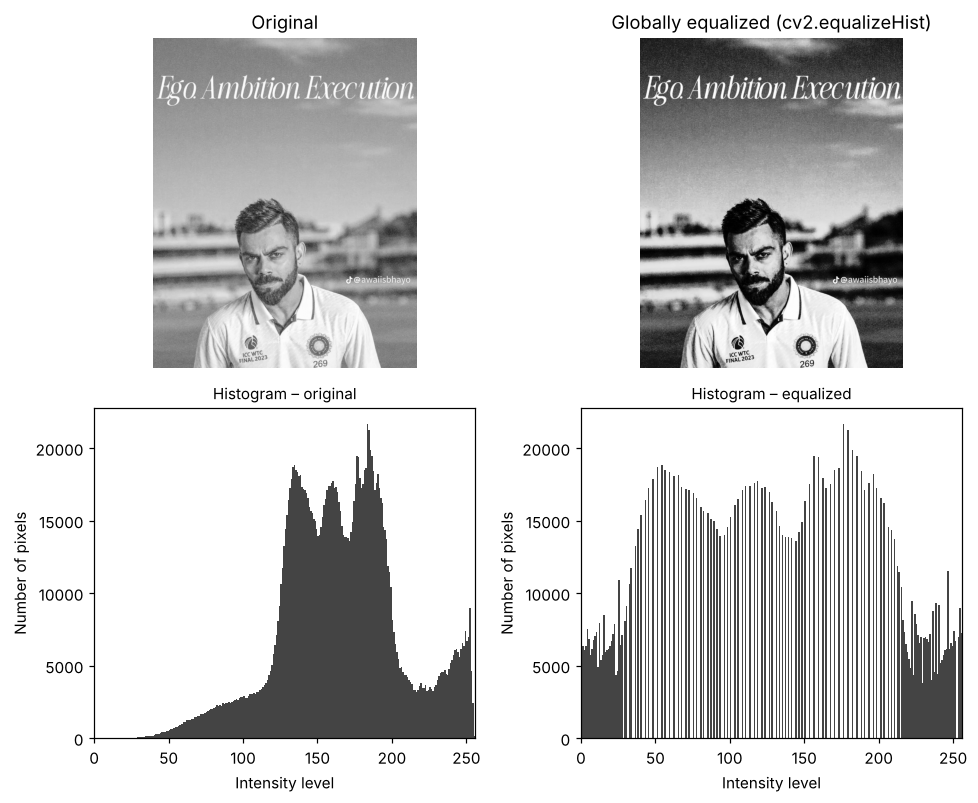

In [17]:
equalized = cv2.equalizeHist(original)

def entropy(a):
    p = np.bincount(a.ravel(), minlength=256) / a.size
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def hf_energy(a):
    """Mean absolute difference from a 3x3 median-filtered copy = simple noise / fine-detail measure."""
    return float(np.abs(a.astype(np.float64) - cv2.medianBlur(a, 3)).mean())

def flattest_block(a, b=16):
    best = (1e9, 0, 0)
    for i in range(0, a.shape[0] - b + 1, b):
        for j in range(0, a.shape[1] - b + 1, b):
            s = a[i:i + b, j:j + b].std()
            if 0.5 < s < best[0]:
                best = (s, i, j)
    return best

_, fi, fj = flattest_block(original)       # a smooth (almost uniform) area of the ORIGINAL image
def flat_std(a):
    return float(a[fi:fi + 16, fj:fj + 16].std())

fig, ax = plt.subplots(2, 2, figsize=(9, 7.4))
ax[0, 0].imshow(original, cmap="gray", vmin=0, vmax=255); ax[0, 0].set_title("Original"); ax[0, 0].axis("off")
ax[0, 1].imshow(equalized, cmap="gray", vmin=0, vmax=255); ax[0, 1].set_title("Globally equalized (cv2.equalizeHist)"); ax[0, 1].axis("off")
hist_ax(ax[1, 0], original, "Histogram – original")
hist_ax(ax[1, 1], equalized, "Histogram – equalized")
plt.tight_layout(); plt.show()

S["eq_std"], S["eq_ent"], S["o_ent"] = float(equalized.std()), entropy(equalized), entropy(original)
S["eq_hf"], S["o_hf"] = hf_energy(equalized), hf_energy(original)
S["eq_flat"], S["o_flat"] = flat_std(equalized), flat_std(original)
S["flat_pos"] = (fi, fj)
print_table("cmp7", "Original vs. global equalization",
            ["Image", "Mean", "Std. dev.", "Entropy (bits)", "Std. dev. in smooth 16×16 patch", "Fine-detail/noise measure"],
            [["Original", original.mean(), original.std(), S["o_ent"], S["o_flat"], S["o_hf"]],
             ["Equalized", equalized.mean(), equalized.std(), S["eq_ent"], S["eq_flat"], S["eq_hf"]]])
print(f"(smooth patch located at rows {fi}-{fi+15}, columns {fj}-{fj+15})")

**Observation:** Equalization stretched the narrow histogram over the full range: the standard deviation rose from 40.1 to 73.6 and the face, hair, beard, jersey and stadium structures show clearly more detail. The price is a much darker, heavier sky (mean 164.9 → 128.5), a comb-like histogram with gaps where levels were merged (entropy 7.25 → 7.02 bits) and stronger noise: the film grain in the smooth sky is amplified – in a smooth 16×16 patch the standard deviation rose from 0.53 to 1.02 and the fine-detail/noise measure from 1.25 to 2.18.

---
## 8. CLAHE (contrast-limited adaptive histogram equalization)
**Task:** Apply cv2.createCLAHE (clipLimit = 2.0, tileGridSize = (8, 8)) and compare with global equalization, especially across uneven lighting.

### Dry run (done before coding)
Four-bin histogram [6, 2, 0, 0] with an absolute cap of 4: clip, redistribute the excess equally (fractions allowed), calculate the new CDF and explain why neighbouring tile mappings need interpolation.

In [18]:
h8 = np.array([6, 2, 0, 0], dtype=float)
cap = 4
clipped = np.minimum(h8, cap)
excess = (h8 - clipped).sum()                  # total clipped away
add = excess / h8.size                         # shared equally over the 4 bins (fractions allowed)
new_h = clipped + add
cum8 = np.cumsum(new_h)
cdf8 = cum8 / new_h.sum()
cdf_unclipped = np.cumsum(h8) / h8.sum()

print_table("dry8", "Dry run 8: clip, redistribute, new CDF  (cap = 4, excess = 2, +0.5 per bin)",
            ["Bin", "Original count", "After clipping", "+ redistributed", "New count", "Cumulative", "New CDF", "CDF without clipping"],
            [[b, h8[b], clipped[b], add, new_h[b], cum8[b], cdf8[b], cdf_unclipped[b]] for b in range(4)])
print("Excess =", excess, "| added per bin =", add, "| total after =", new_h.sum())

check("dry8", "Clipped histogram is [4,2,0,0] with excess 2", np.array_equal(clipped, [4, 2, 0, 0]) and excess == 2)
check("dry8", "New histogram [4.5,2.5,0.5,0.5] and total count unchanged (8)", np.allclose(new_h, [4.5, 2.5, 0.5, 0.5]) and new_h.sum() == 8)
check("dry8", "New CDF [0.5625, 0.875, 0.9375, 1.0]", np.allclose(cdf8, [0.5625, 0.875, 0.9375, 1.0]))

Dry run 8: clip, redistribute, new CDF  (cap = 4, excess = 2, +0.5 per bin)
Bin | Original count | After clipping | + redistributed | New count | Cumulative | New CDF | CDF without clipping
----+----------------+----------------+-----------------+-----------+------------+---------+---------------------
 0  |       6        |       4        |       0.5       |    4.5    |    4.5     |  0.5625 |         0.75        
 1  |       2        |       2        |       0.5       |    2.5    |     7      |  0.875  |          1          
 2  |       0        |       0        |       0.5       |    0.5    |    7.5     |  0.9375 |          1          
 3  |       0        |       0        |       0.5       |    0.5    |     8      |    1    |          1          

Excess = 2.0 | added per bin = 0.5 | total after = 8.0
PASS - Clipped histogram is [4,2,0,0] with excess 2
PASS - New histogram [4.5,2.5,0.5,0.5] and total count unchanged (8)
PASS - New CDF [0.5625, 0.875, 0.9375, 1.0]


**Dry-run explanation**

Clipping: bin 0 holds 6 counts, 2 more than the cap of 4, so 2 counts are removed. Shared equally over four bins this adds 0.5 to each bin, giving [4.5, 2.5, 0.5, 0.5] (the total stays 8). The new CDF is [0.5625, 0.875, 0.9375, 1.0] instead of [0.75, 1, 1, 1] without clipping: the first step of the mapping is smaller, so the dominant bin is stretched less and contrast amplification is limited.

Why interpolation is needed: CLAHE computes a separate mapping for every tile. Two neighbouring pixels on either side of a tile border would be mapped by different curves and could get clearly different outputs, producing visible block edges. OpenCV therefore blends the mappings of the four nearest tile centres with bilinear interpolation, so the transformation changes smoothly across the image.

Note: this is a simplified model. OpenCV redistributes integer counts (and may iterate), and the absolute cap used here is not the clipLimit parameter; for 64×64 tiles and 256 bins clipLimit = 2.0 corresponds to a cap of 2.0 × 4096 / 256 = 32 counts per bin.

### Implementation on the image

tileGridSize = (8, 8) means 8 x 8 = 64 tiles; for this image each tile is 181 x 145 pixels.
Original vs. global equalization vs. CLAHE
       Image        | Std. dev. | Entropy (bits) | Smooth-patch std. dev. | Fine-detail/noise measure
--------------------+-----------+----------------+------------------------+--------------------------
      Original      |   40.054  |     7.2455     |         0.5286         |           1.2548         
Global equalization |  73.5704  |     7.0228     |         1.0208         |           2.1758         
       CLAHE        |  51.3368  |     7.6619     |         1.1446         |           2.439          

Local contrast (std. dev.) in the four quadrants – uneven lighting check
       Image        | Top-left | Top-right | Bottom-left | Bottom-right
--------------------+----------+-----------+-------------+-------------
      Original      | 25.2934  |  24.2153  |   48.7698   |   52.8601   
Global equalization | 55.0589  |  53.8982  |   86.3374   |    90.

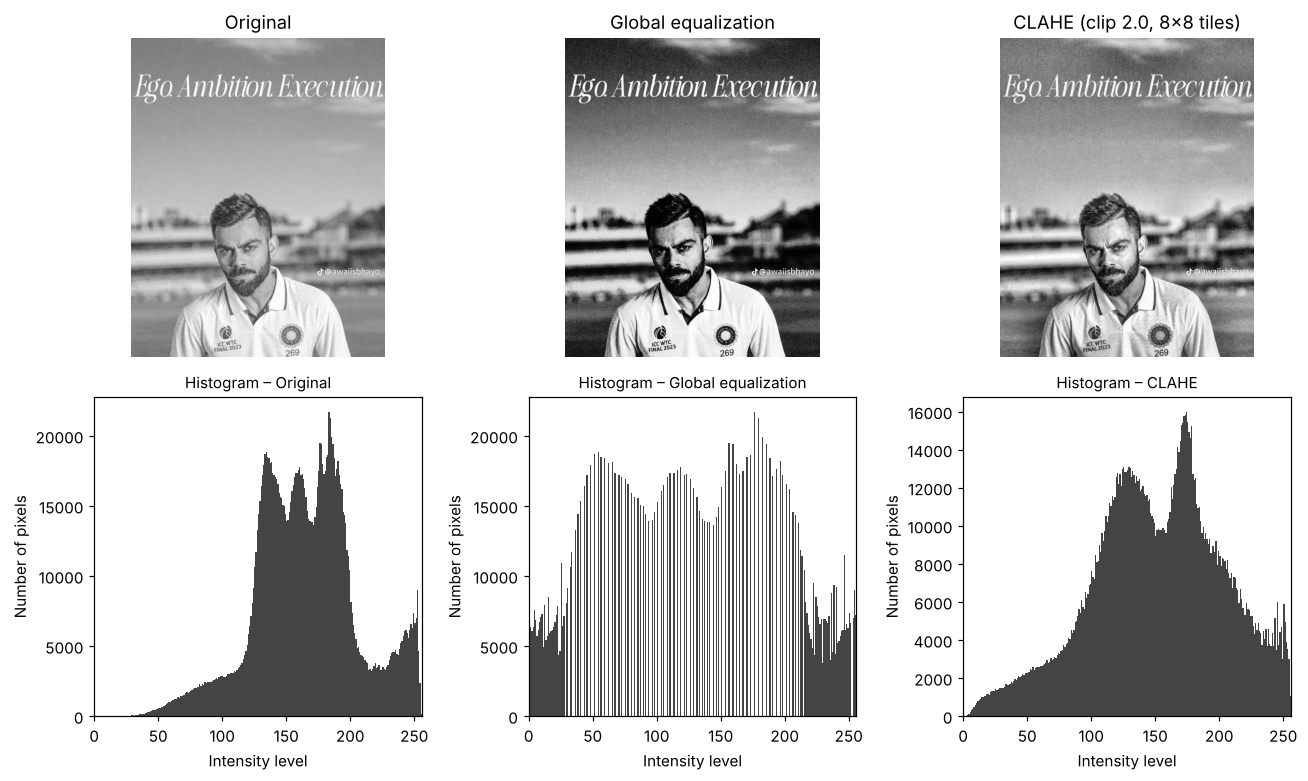

In [19]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img = clahe.apply(original)

th, tw = original.shape[0] // 8, original.shape[1] // 8
print(f"tileGridSize = (8, 8) means 8 x 8 = 64 tiles; for this image each tile is {th} x {tw} pixels.")

fig, ax = plt.subplots(2, 3, figsize=(12, 7.2))
for k, (im, t) in enumerate([(original, "Original"), (equalized, "Global equalization"), (clahe_img, "CLAHE (clip 2.0, 8×8 tiles)")]):
    ax[0, k].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0, k].set_title(t); ax[0, k].axis("off")
    hist_ax(ax[1, k], im, "Histogram – " + t.split(" (")[0])
plt.tight_layout(); plt.show()

def quad_std(a):
    h, w = a.shape
    return [float(a[:h//2, :w//2].std()), float(a[:h//2, w//2:].std()), float(a[h//2:, :w//2].std()), float(a[h//2:, w//2:].std())]

def quad_mean(a):
    h, w = a.shape
    return [float(a[:h//2, :w//2].mean()), float(a[:h//2, w//2:].mean()), float(a[h//2:, :w//2].mean()), float(a[h//2:, w//2:].mean())]

S["cl_flat"], S["cl_hf"], S["cl_ent"], S["cl_std"] = flat_std(clahe_img), hf_energy(clahe_img), entropy(clahe_img), float(clahe_img.std())
S["q_mean"] = {n: quad_mean(a) for n, a in [("o", original), ("g", equalized), ("c", clahe_img)]}
S["q_std"] = {n: quad_std(a) for n, a in [("o", original), ("g", equalized), ("c", clahe_img)]}
print_table("cmp8", "Original vs. global equalization vs. CLAHE",
            ["Image", "Std. dev.", "Entropy (bits)", "Smooth-patch std. dev.", "Fine-detail/noise measure"],
            [["Original", original.std(), S["o_ent"], S["o_flat"], S["o_hf"]],
             ["Global equalization", S["eq_std"], S["eq_ent"], S["eq_flat"], S["eq_hf"]],
             ["CLAHE", S["cl_std"], S["cl_ent"], S["cl_flat"], S["cl_hf"]]])
print_table("cmp8_quad", "Local contrast (std. dev.) in the four quadrants – uneven lighting check",
            ["Image", "Top-left", "Top-right", "Bottom-left", "Bottom-right"],
            [["Original"] + S["q_std"]["o"], ["Global equalization"] + S["q_std"]["g"], ["CLAHE"] + S["q_std"]["c"]])
print_table("cmp8_mean", "Mean intensity in the four quadrants",
            ["Image", "Top-left", "Top-right", "Bottom-left", "Bottom-right"],
            [["Original"] + S["q_mean"]["o"], ["Global equalization"] + S["q_mean"]["g"], ["CLAHE"] + S["q_mean"]["c"]])

**Observation:** CLAHE splits the image into 8 × 8 = 64 tiles (each 181 × 145 pixels here – the tuple (8, 8) counts tiles, not pixels per tile) and limits the contrast gain of each tile (clipLimit = 2.0). The image is unevenly detailed: the top half is smooth sky (local standard deviation 24–25) while the bottom half contains the face, shirt and stadium (49–53). Global equalization applies a single curve: it multiplies the local contrast in every quadrant (to 54–90) but pulls the quadrant means down from about 161–167 to 119–133, giving a dark, harsh result. CLAHE raises local contrast more moderately (to 32–35 in the sky and 63–65 in the lower half) and keeps the quadrant means closer to the original (144–155), so the face and jersey gain detail without darkening the sky as much; it also has the highest entropy (7.66 bits). The cost is noise/texture amplification: the fine-detail/noise measure is 2.44 for CLAHE, 2.18 for global equalization and 1.25 for the original (the measure also counts real texture, so it cannot separate noise from detail).

---
## 9. Fixed binary thresholding
**Task:** Apply cv2.THRESH_BINARY at T = 127, display the binary image and report its unique values.

### Dry run (done before coding)
Pixels [0, 80, 127, 128, 180, 255]: apply r > T → 255 else 0 for T = 127 and T = 180 and compare the white-pixel counts.

In [20]:
P9 = np.array([0, 80, 127, 128, 180, 255])
out127 = np.where(P9 > 127, 255, 0)
out180 = np.where(P9 > 180, 255, 0)
print_table("dry9", "Dry run 9: r > T → 255, otherwise 0",
            ["r", "r > 127 ?", "Output (T = 127)", "r > 180 ?", "Output (T = 180)"],
            [[r_, r_ > 127, a, r_ > 180, b] for r_, a, b in zip(P9, out127, out180)])
print("White pixels: T = 127 ->", int((out127 == 255).sum()), "| T = 180 ->", int((out180 == 255).sum()))

cv127 = cv2.threshold(P9.astype(np.uint8).reshape(1, -1), 127, 255, cv2.THRESH_BINARY)[1].ravel()
cv180 = cv2.threshold(P9.astype(np.uint8).reshape(1, -1), 180, 255, cv2.THRESH_BINARY)[1].ravel()
check("dry9", "T = 127 → [0,0,0,255,255,255] and equals OpenCV", np.array_equal(out127, [0, 0, 0, 255, 255, 255]) and np.array_equal(out127, cv127))
check("dry9", "T = 180 → [0,0,0,0,0,255] and equals OpenCV (180 is NOT > 180)", np.array_equal(out180, [0, 0, 0, 0, 0, 255]) and np.array_equal(out180, cv180))

Dry run 9: r > T → 255, otherwise 0
 r  | r > 127 ? | Output (T = 127) | r > 180 ? | Output (T = 180)
----+-----------+------------------+-----------+-----------------
 0  |     No    |        0         |     No    |        0        
 80 |     No    |        0         |     No    |        0        
127 |     No    |        0         |     No    |        0        
128 |    Yes    |       255        |     No    |        0        
180 |    Yes    |       255        |     No    |        0        
255 |    Yes    |       255        |    Yes    |       255       

White pixels: T = 127 -> 3 | T = 180 -> 1
PASS - T = 127 → [0,0,0,255,255,255] and equals OpenCV
PASS - T = 180 → [0,0,0,0,0,255] and equals OpenCV (180 is NOT > 180)


**Dry-run explanation**

The rule is a strict comparison r > T. For T = 127 the pixel 127 is not greater than 127 and becomes 0, while 128 becomes 255. For T = 180 the pixel 180 is not greater than 180 and becomes 0.

White-pixel count: T = 127 → 3 white pixels (128, 180, 255); T = 180 → 1 white pixel (255). Raising the threshold always reduces (or keeps) the number of white pixels.

### Implementation on the image

Unique values in the binary image: [0, 255]
White pixels: 1449833 (86.08 %)
PASS - Binary image contains only 0 and 255


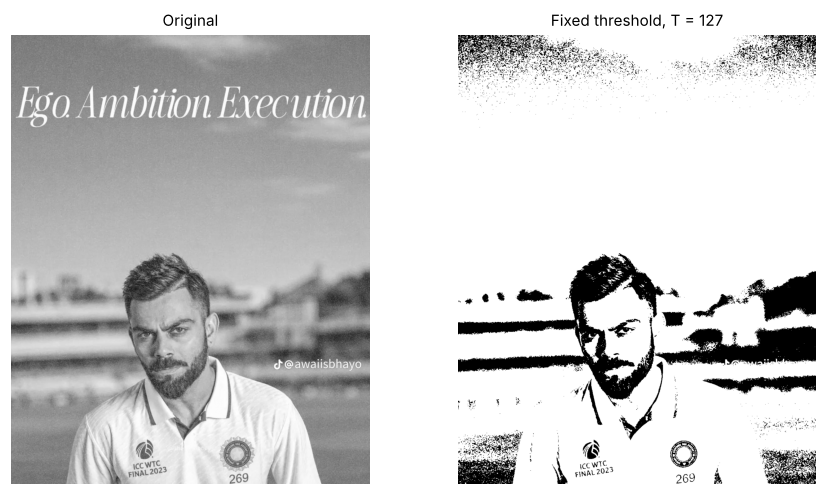

In [21]:
T_fixed, fixed_bin = cv2.threshold(original, 127, 255, cv2.THRESH_BINARY)
print("Unique values in the binary image:", np.unique(fixed_bin).tolist())
S["fixed_white"] = 100 * float((fixed_bin == 255).mean())
print(f"White pixels: {int((fixed_bin == 255).sum())} ({S['fixed_white']:.2f} %)")
show([original, fixed_bin], ["Original", "Fixed threshold, T = 127"], size=4.2)
check("op9", "Binary image contains only 0 and 255", np.array_equal(np.unique(fixed_bin), [0, 255]))

**Observation:** The binary image contains only the values [0, 255] and 86.1 % of the pixels are white. Because this image is bright, T = 127 lies below almost all of the main histogram groups: the sky, the shirt, the stadium and most of the skin become white, and only the darkest parts (hair, beard, eyes, shadows and some grain at the top of the sky) remain black, so a fixed threshold separates the objects poorly.

---
## 10. Otsu thresholding
**Task:** Apply cv2.THRESH_BINARY with cv2.THRESH_OTSU, report the returned threshold and compare its mask with the fixed-threshold mask.

### Dry run (done before coding)
Pixels [0, 1, 4, 5] (no rescaling): try T = 0…4, find w0, w1, μ0, μ1 and w0·w1·(μ0 − μ1)², choose the smallest T among ties, predict the mask and verify with OpenCV.

In [22]:
P10 = np.array([0, 1, 4, 5]); N10 = P10.size
rows, scores = [], []
for T in range(5):
    c0, c1 = P10[P10 <= T], P10[P10 > T]
    w0, w1 = c0.size / N10, c1.size / N10
    m0 = c0.mean() if c0.size else 0.0
    m1 = c1.mean() if c1.size else 0.0
    sb = w0 * w1 * (m0 - m1) ** 2
    scores.append(sb)
    rows.append([T, "{" + ",".join(map(str, c0)) + "}", "{" + ",".join(map(str, c1)) + "}", w0, w1, m0, m1, sb])
print_table("dry10", "Dry run 10: between-class variance for every candidate T",
            ["T", "Class 0 (r ≤ T)", "Class 1 (r > T)", "w0", "w1", "μ0", "μ1", "w0·w1·(μ0 − μ1)²"], rows)

scores = np.array(scores)
T_best = int(np.flatnonzero(np.isclose(scores, scores.max()))[0])        # smallest T among ties
mask_pred = np.where(P10 > T_best, 255, 0)
t_cv, mask_cv = cv2.threshold(P10.astype(np.uint8).reshape(1, -1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Maximum value", scores.max(), "reached at T =", np.flatnonzero(np.isclose(scores, scores.max())).tolist(), "-> chosen T =", T_best)
print("Predicted mask:", mask_pred.tolist(), "| OpenCV mask:", mask_cv.ravel().tolist(), "| OpenCV threshold:", t_cv)

check("dry10", "Tie at T = 1, 2, 3 (value 4.0); smallest T = 1", np.flatnonzero(np.isclose(scores, scores.max())).tolist() == [1, 2, 3] and T_best == 1)
check("dry10", "Predicted mask [0,0,255,255] equals the OpenCV mask", np.array_equal(mask_pred, mask_cv.ravel()))
check("dry10", "OpenCV returns the same threshold (1)", t_cv == T_best)

Dry run 10: between-class variance for every candidate T
T | Class 0 (r ≤ T) | Class 1 (r > T) |  w0  |  w1  |   μ0   |   μ1   | w0·w1·(μ0 − μ1)²
--+-----------------+-----------------+------+------+--------+--------+-----------------
0 |       {0}       |     {1,4,5}     | 0.25 | 0.75 |   0    | 3.3333 |      2.0833     
1 |      {0,1}      |      {4,5}      | 0.5  | 0.5  |  0.5   |  4.5   |        4        
2 |      {0,1}      |      {4,5}      | 0.5  | 0.5  |  0.5   |  4.5   |        4        
3 |      {0,1}      |      {4,5}      | 0.5  | 0.5  |  0.5   |  4.5   |        4        
4 |     {0,1,4}     |       {5}       | 0.75 | 0.25 | 1.6667 |   5    |      2.0833     

Maximum value 4.0 reached at T = [1, 2, 3] -> chosen T = 1
Predicted mask: [0, 0, 255, 255] | OpenCV mask: [0, 0, 255, 255] | OpenCV threshold: 1.0
PASS - Tie at T = 1, 2, 3 (value 4.0); smallest T = 1
PASS - Predicted mask [0,0,255,255] equals the OpenCV mask
PASS - OpenCV returns the same threshold (1)


**Dry-run explanation**

T = 1, 2 and 3 all split the pixels as {0, 1} | {4, 5} because no pixel has a value of 2 or 3, so they give the same between-class variance 4.0, the maximum. The smallest tied threshold, T = 1, is chosen. T = 0 and T = 4 both give only 2.0833.

Predicted mask with r > 1: [0, 0, 255, 255]. OpenCV returns the threshold 1.0 and exactly the same mask.

### Implementation on the image

Threshold returned by Otsu: 165.0
Unique values: [0, 255]
White pixels: fixed 86.08 %  |  Otsu 48.69 %
Pixels where the two masks agree: 62.61 %  (629810 pixels differ)


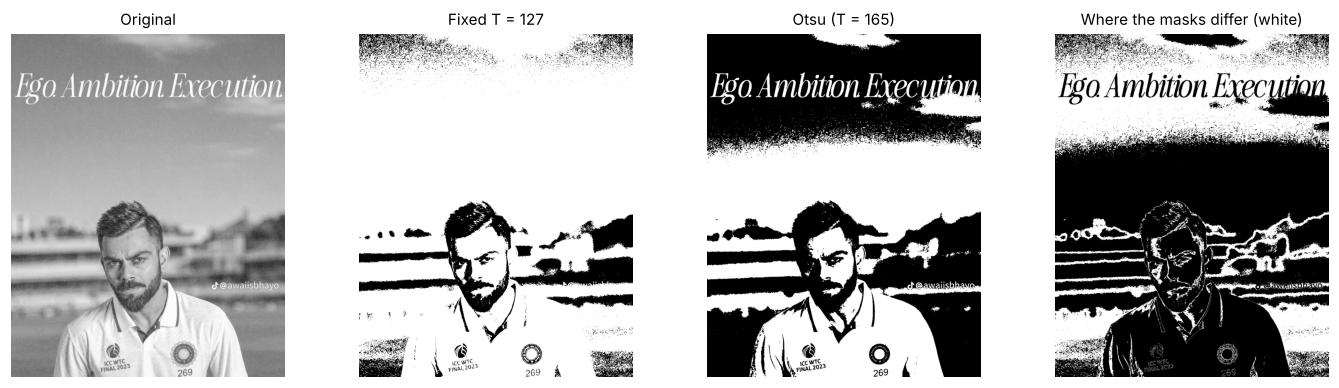

In [23]:
T_otsu, otsu_bin = cv2.threshold(original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Threshold returned by Otsu:", T_otsu)
print("Unique values:", np.unique(otsu_bin).tolist())

diff = (otsu_bin != fixed_bin)
S["T_otsu"] = float(T_otsu)
S["otsu_white"] = 100 * float((otsu_bin == 255).mean())
S["agree"] = 100 * float((~diff).mean())
S["ndiff"] = int(diff.sum())
print(f"White pixels: fixed {S['fixed_white']:.2f} %  |  Otsu {S['otsu_white']:.2f} %")
print(f"Pixels where the two masks agree: {S['agree']:.2f} %  ({S['ndiff']} pixels differ)")

show([original, fixed_bin, otsu_bin, diff.astype(np.uint8) * 255],
     ["Original", "Fixed T = 127", f"Otsu (T = {T_otsu:.0f})", "Where the masks differ (white)"], ncols=4, size=3.2)

**Observation:** Otsu chose T = 165 automatically by maximising the between-class variance; it lies between the middle and the upper histogram peaks and gives 48.7 % white pixels against 86.1 % for T = 127. The two masks agree on 62.6 % of the pixels; the 629,810 pixels that differ are exactly those with values from 128 to 165, which are white for the fixed threshold but black for Otsu. Otsu's mask separates the bright shirt, clouds and lettering from the darker sky, face and background better than the fixed threshold, because T was taken from this image's own histogram instead of being guessed.

---
## 11. Adaptive Gaussian thresholding
**Task:** Apply cv2.adaptiveThreshold (Gaussian weighting, binary output, blockSize = 11, C = 2) and compare with the fixed and Otsu thresholds.

### Dry run (done before coding)
Neighbourhood [[100,100,100],[100,120,140],[140,140,140]] with Gaussian weights [[1,2,1],[2,4,2],[1,2,1]]/16: weighted mean, T = mean − 2, classify the centre pixel and a pixel equal to T.

In [24]:
nb = np.array([[100, 100, 100], [100, 120, 140], [140, 140, 140]], dtype=float)
wt = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16.0
prod = nb * wt
wmean = prod.sum()
T11 = wmean - 2                                   # T = mean − C, with C = 2

print_table("dry11_prod", "Dry run 11(a): pixel × Gaussian weight (weights = [1 2 1; 2 4 2; 1 2 1] / 16)",
            ["Row", "Col 1", "Col 2", "Col 3", "Row sum"],
            [[i + 1, *prod[i], prod[i].sum()] for i in range(3)])
center = nb[1, 1]
out_center = 255 if center > T11 else 0
equal_px = T11                                    # a pixel whose value equals T
out_equal = 255 if equal_px > T11 else 0
print_table("dry11_res", "Dry run 11(b): threshold and classification",
            ["Quantity", "Value"],
            [["Weighted mean", wmean], ["C", 2], ["T = mean − C", T11],
             ["Centre pixel r", center], ["r > T ?", center > T11], ["Output for the centre pixel", out_center],
             ["A pixel with r = T (118)", equal_px], ["r > T ?", equal_px > T11], ["Output for that pixel", out_equal]])

cv_ad = cv2.adaptiveThreshold(nb.astype(np.uint8), 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 3, 2)
check("dry11", "Weighted mean = 120 and T = 118", np.isclose(wmean, 120) and np.isclose(T11, 118))
check("dry11", "Centre pixel 120 > 118 → 255, equal-to-T pixel → 0", out_center == 255 and out_equal == 0)
check("dry11", "OpenCV (blockSize = 3, C = 2) also gives 255 for the centre pixel", cv_ad[1, 1] == 255)

Dry run 11(a): pixel × Gaussian weight (weights = [1 2 1; 2 4 2; 1 2 1] / 16)
Row | Col 1 | Col 2 | Col 3 | Row sum
----+-------+-------+-------+--------
 1  |  6.25 |  12.5 |  6.25 |    25  
 2  |  12.5 |   30  |  17.5 |    60  
 3  |  8.75 |  17.5 |  8.75 |    35  

Dry run 11(b): threshold and classification
          Quantity          | Value
----------------------------+------
       Weighted mean        |  120 
             C              |   2  
        T = mean − C        |  118 
       Centre pixel r       |  120 
          r > T ?           |  Yes 
Output for the centre pixel |  255 
  A pixel with r = T (118)  |  118 
          r > T ?           |   No 
   Output for that pixel    |   0  

PASS - Weighted mean = 120 and T = 118
PASS - Centre pixel 120 > 118 → 255, equal-to-T pixel → 0
PASS - OpenCV (blockSize = 3, C = 2) also gives 255 for the centre pixel


**Dry-run explanation**

Weighted mean = (400 + 960 + 560) / 16 = 120 (row sums of the product table: 25 + 60 + 35). T = 120 − 2 = 118.

The centre pixel 120 > 118, so its output is 255. A pixel equal to T (118) is not greater than T, so its output is 0 – the comparison is strict.

OpenCV (blockSize = 3, C = 2) gives 255 for the centre pixel, which agrees with the hand calculation. For the image task blockSize = 11 is used.

### Implementation on the image

Unique values: [0, 255]
Comparison of the three thresholding methods
             Method              |    Threshold     | % white pixels | % agreement with adaptive
---------------------------------+------------------+----------------+--------------------------
        Fixed (T = 127)          |   global, 127    |    86.0782     |          75.8127         
              Otsu               |   global, 165    |    48.6857     |          62.4808         
Adaptive Gaussian (11×11, C = 2) | local, per pixel |    73.8123     |            100           



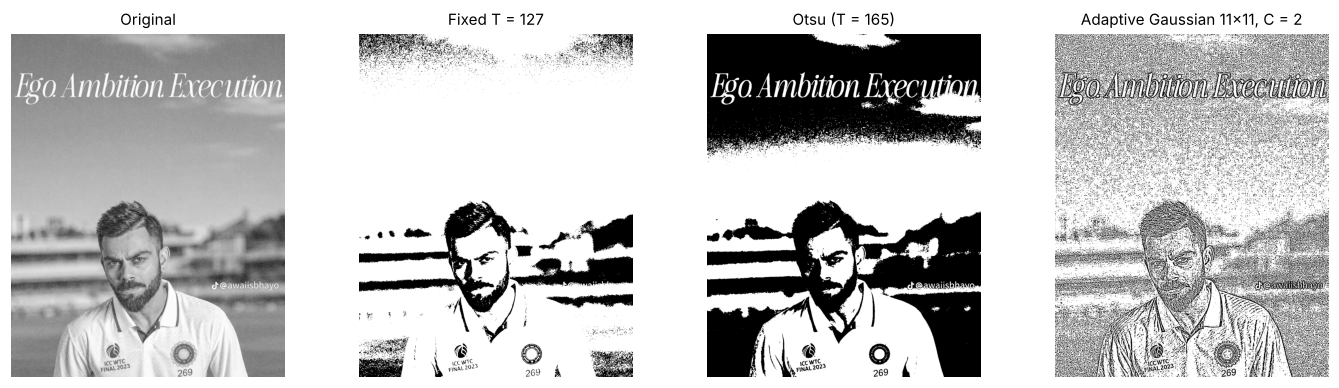

In [25]:
adaptive_bin = cv2.adaptiveThreshold(original, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, blockSize=11, C=2)
S["adapt_white"] = 100 * float((adaptive_bin == 255).mean())
S["agree_ad_fixed"] = 100 * float((adaptive_bin == fixed_bin).mean())
S["agree_ad_otsu"] = 100 * float((adaptive_bin == otsu_bin).mean())
S["agree_fx_otsu"] = S["agree"]
print("Unique values:", np.unique(adaptive_bin).tolist())
print_table("cmp11", "Comparison of the three thresholding methods",
            ["Method", "Threshold", "% white pixels", "% agreement with adaptive"],
            [["Fixed (T = 127)", "global, 127", S["fixed_white"], S["agree_ad_fixed"]],
             ["Otsu", f"global, {T_otsu:.0f}", S["otsu_white"], S["agree_ad_otsu"]],
             ["Adaptive Gaussian (11×11, C = 2)", "local, per pixel", S["adapt_white"], 100.0]])
show([original, fixed_bin, otsu_bin, adaptive_bin],
     ["Original", "Fixed T = 127", f"Otsu (T = {T_otsu:.0f})", "Adaptive Gaussian 11×11, C = 2"], ncols=4, size=3.2)

**Observation:** The adaptive result has 73.8 % white pixels and agrees with the fixed and Otsu masks on 75.8 % and 62.5 % of the pixels. Each pixel is compared with the Gaussian-weighted mean of its own 11 × 11 neighbourhood minus 2, so the output follows local edges and fine structure (eyes, eyebrows, hair, beard, lettering, logos) whatever the absolute brightness is, while smooth areas such as the sky and the blurred stadium become mostly white with salt-and-pepper speckle caused by the film grain. Local thresholds help when illumination is uneven (shadows, gradients, scanned documents) or when fine detail matters; global thresholds are better when the lighting is uniform and the histogram has clearly separated groups.

---
## Key concepts
**Clipping.** Clipping forces every value that falls outside the valid range 0–255 to the nearest limit (negative values become 0, values above 255 become 255; np.clip). It keeps the order of the grey levels but destroys the differences between all values that are pushed to the same limit, so detail is lost in shadows and highlights.

**Overflow.** uint8 arithmetic is modulo 256: 240 + 40 gives 24 and 30 − 40 gives 246 instead of 255 and 0. NumPy does not warn for arrays. The safe procedure is to convert to a wider type (int16 or float) before the arithmetic, clip to 0–255 and only then convert back to uint8 (conversion of floats truncates the fraction).

**Brightness versus contrast.** Brightness is an additive shift (s = r + β): every pixel moves by the same amount, so the mean changes but the differences between pixels stay the same, until clipping occurs. Contrast is a multiplicative change of the spread (s = αr, or s = (r − 128)α + 128 around a pivot): it changes the differences between pixels. Multiplying from zero also moves the mean, so it mixes both effects, while the centered form keeps the pivot 128 fixed.

**Gamma convention.** This lab uses s = 255 (r/255)^γ: γ < 1 expands the dark values and brightens the image, γ > 1 compresses them and darkens it, and 0 and 255 never change. Other sources (display gamma, some libraries) use the inverse exponent 1/γ, which reverses the meaning of γ < 1 and γ > 1.

**Global versus local enhancement.** Global methods (equalizeHist) apply one mapping to the whole image; they are quick and suitable when the lighting is fairly uniform, but they can amplify noise and fail in unevenly lit scenes. Local methods (CLAHE) compute a mapping per tile with a limited contrast gain, which brings out detail in both dark and bright areas at the cost of more texture/noise amplification and two parameters (clip limit, tile grid).

**Global versus local thresholding.** Global thresholds (fixed or Otsu) are useful when the background is evenly lit and the histogram shows separated groups; Otsu chooses the threshold automatically. Adaptive thresholds compare each pixel with its local mean minus a constant and are useful for uneven illumination, shadows and documents, but they respond to every small local change, so smooth areas and noise can look speckled; blockSize and C must be tuned.

---
## Final check

In [26]:
# Integrity: the original image must still be exactly what was loaded from disk
reloaded = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
check("final", "The original image was never modified", np.array_equal(original, reloaded))
total = sum(len(v) for v in checks_log.values())
passed = sum(ok for v in checks_log.values() for _, ok in v)
print(f"\nAll verification checks: {passed} / {total} passed.")
print("Student:", STUDENT_NAME, "| Roll No:", ROLL_NO)

PASS - The original image was never modified

All verification checks: 37 / 37 passed.
Student: Sahadat Ali | Roll No: 2024-SE-36
